In [1]:
import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split


In [2]:
train_data = pd.read_csv("sign_mnist_train.csv")
test_data = pd.read_csv("sign_mnist_test.csv")
print(train_data.shape)
print(test_data.shape)

(27455, 785)
(7172, 785)


In [7]:
x_train = train_data.drop("label",axis=1).values
y_train = train_data["label"].values

x_test = test_data.drop("label",axis=1).values
y_test = test_data["label"].values

x_train = x_train/255.0
x_test = x_test/255.0

x_train = x_train.reshape(-1,28,28,1)
x_test = x_test.reshape(-1,28,28,1)

print(x_train.shape)
print(x_test.shape)

(27455, 28, 28, 1)
(7172, 28, 28, 1)


In [11]:
x_train,x_val,y_train,y_val = train_test_split(
    x_train,y_train,test_size=0.1,random_state=42,stratify=y_train
)

print(x_train.shape)
print(x_val.shape)

(15813, 28, 28, 1)
(1758, 28, 28, 1)


In [17]:
model = keras.Sequential([
    keras.Input(shape=(28,28,1)),
    layers.Conv2D(32,(3,3),activation="relu"),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(25,activation="softmax")

])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)                    │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 5408)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 25)                  │         135,225 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 135,545 (529.47 KB)

 Trainable params: 135,545 (529.47 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
model.compile(
    optimizer="adam",
    loss = "sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [20]:
history = model.fit(
    x_train,
    y_train,
    batch_size=64,
    epochs=10,
    validation_data = (x_val,y_val)
)

Epoch 1/10
248/248 ━━━━━━━━━━━━━━━━━━━━ 10s 27ms/step - accuracy: 0.5674 - loss: 1.7516 - val_accuracy: 0.8049 - val_loss: 0.8010
Epoch 2/10
248/248 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.8761 - loss: 0.5475 - val_accuracy: 0.9329 - val_loss: 0.3657
Epoch 3/10
248/248 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - accuracy: 0.9524 - loss: 0.2653 - val_accuracy: 0.9710 - val_loss: 0.2054
Epoch 4/10
248/248 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.9852 - loss: 0.1427 - val_accuracy: 0.9858 - val_loss: 0.1220
Epoch 5/10
248/248 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.9956 - loss: 0.0854 - val_accuracy: 0.9977 - val_loss: 0.0712
Epoch 6/10
248/248 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - accuracy: 0.9991 - loss: 0.0529 - val_accuracy: 0.9983 - val_loss: 0.0446
Epoch 7/10
248/248 ━━━━━━━━━━━━━━━━━━━━ 7s 29ms/step - accuracy: 0.9992 - loss: 0.0373 - val_accuracy: 1.0000 - val_loss: 0.0303
Epoch 8/10
248/248 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - accuracy: 0.9998 - loss: 0.0257 - val_acc

In [21]:
loss, accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

225/225 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.8203 - loss: 0.6710
Test Loss: 0.6710098385810852
Test Accuracy: 0.8202732801437378


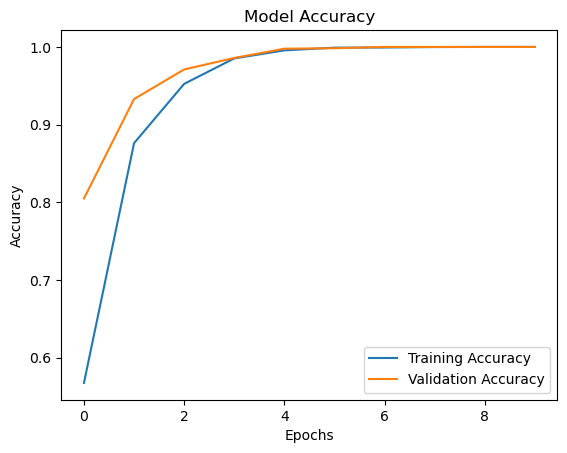

In [22]:
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

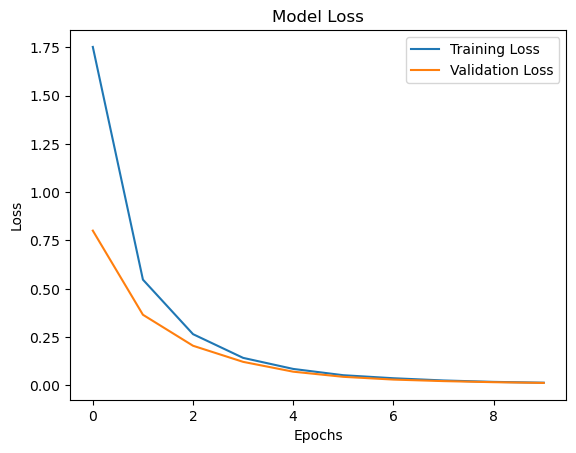

In [23]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [24]:
prediction = model.predict(x_test[:1])

print("Predicted Label:", np.argmax(prediction[0]))
print("Actual Label:", y_test[0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 176ms/step
Predicted Label: 6
Actual Label: 6


In [ ]:
import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split

train_data = pd.read_csv("sign_mnist_train.csv")
test_data = pd.read_csv("sign_mnist_test.csv")
print(train_data.shape)
print(test_data.shape)

x_train = train_data.drop("label",axis=1).values
y_train = train_data["label"].values

x_test = test_data.drop("label",axis=1).values
y_test = test_data["label"].values

x_train = x_train/255.0
x_test = x_test/255.0

x_train = x_train.reshape(-1,28,28,1)
x_test = x_test.reshape(-1,28,28,1)

print(x_train.shape)
print(x_test.shape)


x_train,x_val,y_train,y_val = train_test_split(
    x_train,y_train,test_size=0.1,random_state=42,stratify=y_train
)

print(x_train.shape)
print(x_val.shape)

model = keras.Sequential([
    keras.Input(shape=(28,28,1)),
    layers.Conv2D(32,(3,3),activation="relu"),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(25,activation="softmax")

])
model.summary()

model.compile(
    optimizer="adam",
    loss = "sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    x_train,
    y_train,
    batch_size=64,
    epochs=10,
    validation_data = (x_val,y_val)
)

loss, accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

prediction = model.predict(x_test[:1])

print("Predicted Label:", np.argmax(prediction[0]))
print("Actual Label:", y_test[0])